# Vocal-aware chord analysis

BTC analyzes the original mix. HDemucs isolates vocals for CREPE, and brief BTC label flicker is smoothed before compatibility scoring.

In [1]:
import os
from pathlib import Path
import matplotlib.pyplot as plt

from reharmonize_models import (
    aggregate_melody_by_chord, detect_chords, melody_clash_score,
    melody_pitch_track, save_lab, separate_vocals, smooth_chord_intervals,
)

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
audio_setting = os.environ.get('AUDIO_PATH')
AUDIO = Path(audio_setting) if audio_setting else ROOT / 'data/song.mp3'
if not AUDIO.is_absolute():
    AUDIO = ROOT / AUDIO
DURATION = float(os.environ.get('ANALYSIS_DURATION', '30'))
AUDIO, DURATION

(PosixPath('/Users/danendra/Documents/ADA26/C6/Models/data/song.mp3'), 30.0)

In [2]:
VOCALS = ROOT / 'artifacts' / f'{AUDIO.stem}-vocals.wav'
separate_vocals(AUDIO, VOCALS, duration=DURATION)
VOCALS

100%|██████████████████████████████████████████████████████████████████████| 319M/319M [04:06<00:00, 1.36MB/s]


PosixPath('/Users/danendra/Documents/ADA26/C6/Models/artifacts/song-vocals.wav')

In [3]:
raw_chords = detect_chords(AUDIO, btc_root=ROOT / 'vendor/BTC-ISMIR19', duration=DURATION)
chords = smooth_chord_intervals(raw_chords, minimum_duration=0.35)
save_lab(chords, ROOT / 'artifacts' / f'{AUDIO.stem}-smoothed.lab')
print({'raw_intervals': len(raw_chords), 'smoothed_intervals': len(chords)})
chords

{'raw_intervals': 17, 'smoothed_intervals': 15}


,start,end,chord
0,0.000000,1.111111,N
1,1.111111,6.388889,E
2,6.388889,8.333333,A
3,8.333333,12.500000,E
4,12.500000,14.074074,E:7
5,14.074074,16.018519,A
6,16.018519,19.259259,E
7,19.259259,20.000000,B
8,20.000000,21.574074,E:7
9,21.574074,23.425926,A


In [4]:
melody = melody_pitch_track(VOCALS, duration=DURATION, periodicity_threshold=0.5)
segments = aggregate_melody_by_chord(chords, melody)
segments['clash'] = segments.apply(
    lambda row: melody_clash_score(row.melody_profile, row.chord), axis=1
)
segments[['start', 'end', 'chord', 'voiced_frames', 'clash']]

,start,end,chord,voiced_frames,clash
0,0.000000,1.111111,N,81,0.000000
1,1.111111,6.388889,E,5,1.000000
2,6.388889,8.333333,A,1,0.000000
3,8.333333,12.500000,E,20,0.961444
4,12.500000,14.074074,E:7,105,0.086173
5,14.074074,16.018519,A,115,0.338929
6,16.018519,19.259259,E,11,1.000000
7,19.259259,20.000000,B,11,1.000000
8,20.000000,21.574074,E:7,43,0.625962
9,21.574074,23.425926,A,151,0.634392


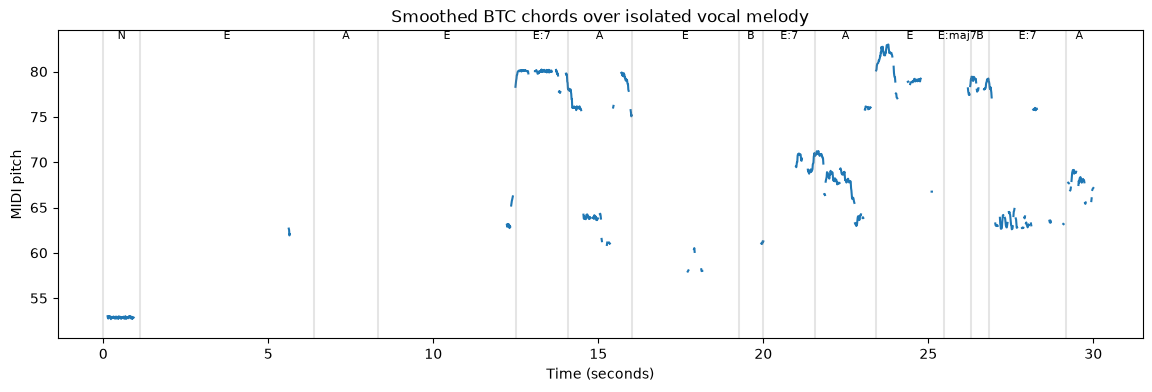

In [5]:
ax = melody.plot(x='time', y='midi', figsize=(14, 4), legend=False, title='Smoothed BTC chords over isolated vocal melody')
for row in chords.itertuples(index=False):
    ax.axvline(row.start, color='gray', alpha=0.2)
    ax.text((row.start + row.end) / 2, ax.get_ylim()[1], row.chord, ha='center', va='top', fontsize=8)
ax.set(xlabel='Time (seconds)', ylabel='MIDI pitch')
plt.show()